# ECII vs One-vs-Rest ECII vs MC-ECII – Preprocessing and Coding Comparison

Shows, **in code and on your data**, why a class-aware multiclass extension (MC-ECII) is needed on top of binary ECII.

Upload **`Processed_Student_Stress_Data_Final.csv`** when asked (any processed CSV with the same columns works).

> **Honest scope note.** The original ECII (Sarker & Hitzler, AAAI 2019) works on an OWL ontology with a DL reasoner. Here the three learners are **compact re-implementations of the same ideas on a reasoner-derived binary predicate matrix**:
> top-down candidate generation, coverage-based quality, pruning, and (for MC-ECII) class-wise coverage Cov(c,k), coverage vector V(c), Class(c) = argmax with margin, class scoring and abstention.
> "Coverage evaluations" are used as a proxy for DL-reasoner calls. These are a **prototype comparison**, not a replacement for the full implementation in your final repository.

## 1. Setup and data

In [ ]:
import warnings; warnings.filterwarnings('ignore')
import os, time, shutil
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 110
os.makedirs('outputs', exist_ok=True)
RANDOM_STATE = 42; CLASSES = ['Low', 'Medium', 'High']

CSV_NAME = 'Processed_Student_Stress_Data.csv'
try:
    from google.colab import files
    if not os.path.exists(CSV_NAME):
        up = files.upload(); CSV_NAME = list(up.keys())[0]
except ImportError:
    pass
df = pd.read_csv(CSV_NAME); print(df.shape)

(2066, 33)


## 2. Preprocessing – steps shared by all three methods
Same split, same leakage control, same thresholds (from the **training split only**) for every method, so the comparison is fair.

In [ ]:
leak_cols = [c for c in df.columns if c.startswith('Stress_Item_')] + ['Stress_Score']   # define the target -> never used
idx_tr, idx_te = train_test_split(df.index, test_size=0.20, stratify=df['Stress_Level'], random_state=RANDOM_STATE)
train, test = df.loc[idx_tr], df.loc[idx_te]
y_tr, y_te = train['Stress_Level'].values, test['Stress_Level'].values
print('train', len(train), '| test', len(test), '| leakage columns excluded:', len(leak_cols))

train 1652 | test 414 | leakage columns excluded: 13


In [ ]:
# Ontology-style 'level' concepts. Numeric: Low <= 33rd pct, High >= 67th pct, Mid in between (TRAIN quantiles).
# Categorical: one concept per level. Each concept = a DL class such as  HighAnxiety ≡ Student ⊓ ∃hasAnxietyLevel.[≥ 7]
NUM = ['Study_Hours', 'Sleep_Hours', 'Class_Attendance', 'Social_Media_Use', 'Screen_Time', 'Anxiety_Level']
CAT = ['Exam_Frequency', 'Assignment_Load', 'Physical_Exercise', 'Peer_Pressure', 'Family_Support',
       'Family_Income_Level', 'Tuition', 'University_Type']

def make_atoms(t):
    atoms = []
    for c in NUM:
        q1, q2 = t[c].quantile([1/3, 2/3]).round(1)
        atoms += [(f'Low_{c}', c, '<=', q1), (f'Mid_{c}', c, 'between', (q1, q2)), (f'High_{c}', c, '>=', q2)]
    for c in CAT:
        atoms += [(f'{c}={v}', c, '==', v) for v in sorted(t[c].unique())]
    return atoms

def holds(v, op, thr):
    if op == '>=': return v >= thr
    if op == '<=': return v <= thr
    if op == 'between': return (v > thr[0]) & (v < thr[1])
    return v == thr

def to_matrix(d, atoms):                       # reasoner-style output: students x binary concepts
    return np.column_stack([holds(d[c], op, thr) for _, c, op, thr in atoms]).astype(bool)

atoms = make_atoms(train); atom_names = [a[0] for a in atoms]
B_tr, B_te = to_matrix(train, atoms), to_matrix(test, atoms)
print('binary concepts:', B_tr.shape[1], '| avg concepts true per student:', B_tr.sum(1).mean().round(1))
pd.DataFrame(atoms, columns=['Concept', 'Column', 'Operator', 'Threshold']).head(12)

binary concepts: 42 | avg concepts true per student: 14.0


,Concept,Column,Operator,Threshold
0,Low_Study_Hours,Study_Hours,<=,5.0
1,Mid_Study_Hours,Study_Hours,between,"(5.0, 7.0)"
2,High_Study_Hours,Study_Hours,>=,7.0
3,Low_Sleep_Hours,Sleep_Hours,<=,6.0
4,Mid_Sleep_Hours,Sleep_Hours,between,"(6.0, 7.0)"
5,High_Sleep_Hours,Sleep_Hours,>=,7.0
6,Low_Class_Attendance,Class_Attendance,<=,73.0
7,Mid_Class_Attendance,Class_Attendance,between,"(73.0, 83.0)"
8,High_Class_Attendance,Class_Attendance,>=,83.0
9,Low_Social_Media_Use,Social_Media_Use,<=,3.0


## 3. Preprocessing – what is DIFFERENT for each method
The shared matrix `B` is the same. What changes is **how the target is prepared** and **what the learner receives**.

In [ ]:
# ECII (binary): can only separate TWO groups. For a 3-class problem you must choose a pair (here High vs Low, Medium dropped)
mask_bin_tr = np.isin(y_tr, ['High', 'Low'])
ecii_in  = dict(B=B_tr[mask_bin_tr], y_pos=(y_tr[mask_bin_tr] == 'High'))

# One-vs-rest ECII: three separate binary relabellings of the SAME data
ovr_in = {k: dict(B=B_tr, y_pos=(y_tr == k)) for k in CLASSES}

# MC-ECII: ONE target with all classes kept; class-wise coverage is computed from it
mc_in = dict(B=B_tr, y=y_tr)

rows = [
 {'Method': 'ECII (binary)', 'Target given to learner': 'High (positive) vs Low (negative)', 'Learner runs': 1,
  'Training rows used': int(mask_bin_tr.sum()), 'Rows dropped': int((~mask_bin_tr).sum()),
  'Positives / Negatives': f"{ecii_in['y_pos'].sum()} / {(~ecii_in['y_pos']).sum()}", 'Classes it can predict': 2},
 {'Method': 'One-vs-rest ECII', 'Target given to learner': 'k vs rest, for k in Low/Medium/High', 'Learner runs': 3,
  'Training rows used': len(y_tr), 'Rows dropped': 0,
  'Positives / Negatives': ' | '.join(f"{k}: {(y_tr==k).sum()}/{(y_tr!=k).sum()}" for k in CLASSES), 'Classes it can predict': 3},
 {'Method': 'MC-ECII', 'Target given to learner': 'Low / Medium / High together (RiskClass)', 'Learner runs': 1,
  'Training rows used': len(y_tr), 'Rows dropped': 0,
  'Positives / Negatives': 'n/a - class-wise coverage Cov(c,k) per class', 'Classes it can predict': 3},
]
prep_table = pd.DataFrame(rows).set_index('Method'); prep_table.to_csv('outputs/preprocessing_comparison.csv'); prep_table.T

Method,ECII (binary),One-vs-rest ECII,MC-ECII
Target given to learner,High (positive) vs Low (negative),"k vs rest, for k in Low/Medium/High",Low / Medium / High together (RiskClass)
Learner runs,1,3,1
Training rows used,1046,1652,1652
Rows dropped,606,0,0
Positives / Negatives,487 / 559,Low: 559/1093 | Medium: 606/1046 | High: 487/1165,"n/a - class-wise coverage Cov(c,k) per class"
Classes it can predict,2,3,3


In [ ]:
# One student, as each method sees the target
s = 0
print('Student', train.index[s], '| true class:', y_tr[s])
print(' ECII (binary)      : only usable if class in {High, Low}; Medium student would be DROPPED ->', y_tr[s] in ('High', 'Low'))
print(' One-vs-rest ECII   :', {k: bool(y_tr[s] == k) for k in CLASSES}, '(three independent binary labels)')
print(' MC-ECII            : RiskClass =', y_tr[s], '(single multiclass label, contributes to V(c) for every concept it satisfies)')

Student 1573 | true class: Medium
 ECII (binary)      : only usable if class in {High, Low}; Medium student would be DROPPED -> False
 One-vs-rest ECII   : {'Low': False, 'Medium': True, 'High': False} (three independent binary labels)
 MC-ECII            : RiskClass = Medium (single multiclass label, contributes to V(c) for every concept it satisfies)


## 4. Coding – the three learners

### 4a. Shared candidate generation (top-down refinement with pruning)
Both ECII and MC-ECII keep this machinery. It takes a *quality function* `q(mask)` and returns refined concepts (conjunctions of binary concepts). **This is the code that stays unchanged.**

In [ ]:
class EvalCounter: n = 0
def new_counter(): c = EvalCounter(); c.n = 0; return c

def cover(B, idx):
    m = np.ones(B.shape[0], bool)
    for j in idx: m &= B[:, j]
    return m

def refine(B, quality, min_support, beam, max_len, counter):
    """ECII-style candidate generation: start from atomic concepts, specialise by adding a conjunct,
    prune by minimum support and keep only the best `beam` candidates per level."""
    m = B.shape[1]; found, frontier = {}, []
    for j in range(m):
        mask = B[:, j]; counter.n += 1
        if mask.sum() >= min_support: found[(j,)] = (mask, quality(mask)); frontier.append((j,))
    for _ in range(2, max_len + 1):
        cand = {}
        for idx in frontier:
            for j in range(idx[-1] + 1, m):
                new = idx + (j,); mask = found[idx][0] & B[:, j]; counter.n += 1     # one coverage evaluation
                if mask.sum() >= min_support: cand[new] = (mask, quality(mask))
        frontier = [k for k, _ in sorted(cand.items(), key=lambda kv: -kv[1][1])[:beam]]
        for k in frontier: found[k] = cand[k]
    return found

### 4b. ECII (binary) – the part that is binary-specific
* **quality** = positive coverage minus negative coverage (TPR − FPR)
* **prediction** = positive if any learned concept matches

In [ ]:
class ECII:
    def __init__(self, min_support=15, beam=80, max_len=3, K=10, theta=0.05):
        self.min_support, self.beam, self.max_len, self.K, self.theta = min_support, beam, max_len, K, theta
    def fit(self, B, y_pos):
        P, N = y_pos.sum(), (~y_pos).sum(); self.counter = new_counter()
        quality = lambda m: (m & y_pos).sum() / P - (m & ~y_pos).sum() / N           # binary coverage heuristic
        found = refine(B, quality, self.min_support, self.beam, self.max_len, self.counter)
        self.concepts = sorted([(k, v[1]) for k, v in found.items() if v[1] >= self.theta], key=lambda kv: -kv[1])[:self.K]
        return self
    def predict(self, B):                                                              # disjunction of concepts
        return np.column_stack([cover(B, k) for k, _ in self.concepts]).any(1) if self.concepts else np.zeros(len(B), bool)

### 4c. One-vs-rest ECII – the naive workaround
Three independent ECII runs, then a hand-written rule to combine them (needed because nothing decides between conflicting answers).

In [ ]:
class OneVsRestECII:
    def __init__(self, **kw): self.kw = kw
    def fit(self, B, y):
        self.models = {k: ECII(**self.kw).fit(B, y == k) for k in CLASSES}                # 3 separate runs
        self.evals = sum(m.counter.n for m in self.models.values()); return self
    def hits(self, B):
        return np.column_stack([self.models[k].predict(B) for k in CLASSES])
    def predict(self, B, resolve=True, default='Medium'):
        H = self.hits(B); out, status = [], []
        best_q = {k: {} for k in CLASSES}
        for i, row in enumerate(H):
            if row.sum() == 1:  out.append(CLASSES[int(row.argmax())]); status.append('one class (clean)')
            elif row.sum() == 0: out.append(default if resolve else None); status.append('no class matched')
            else:                                                                           # several classes matched
                if resolve:   # ad-hoc tie-break: class owning the highest-quality matched concept
                    qs = {CLASSES[j]: max(q for (c, q) in self.models[CLASSES[j]].concepts if cover(B[i:i+1], c)[0]) for j in np.where(row)[0]}
                    out.append(max(qs, key=qs.get))
                else: out.append(None)
                status.append('conflict (several classes)')
        return np.array(out, dtype=object), np.array(status)

### 4d. MC-ECII – the class-aware extension
Same `refine()` – only these parts are new:
* **quality** = margin between the best and second-best *normalised* class coverage (from the coverage vector V(c))
* **Class(c)** = argmax of normalised Cov(c,k), kept only if the margin ≥ δ
* **prediction** = score_k(x) = matched concepts of class k / total concepts of class k → argmax, or **abstain**

In [ ]:
class MCECII:
    def __init__(self, min_support=15, beam=80, max_len=3, K=25, delta=0.02):
        self.min_support, self.beam, self.max_len, self.K, self.delta = min_support, beam, max_len, K, delta
    def vector(self, mask, y):                                                             # coverage vector V(c), normalised per class
        return np.array([(mask & (y == k)).sum() / (y == k).sum() for k in CLASSES])
    def fit(self, B, y):
        self.counter = new_counter()
        quality = lambda m: np.sort(self.vector(m, y))[::-1][:2] @ np.array([1, -1])      # margin of best vs second class
        found = refine(B, quality, self.min_support, self.beam, self.max_len, self.counter)   # ONE shared pass for all classes
        self.concepts = {k: [] for k in CLASSES}
        for idx, (mask, q) in sorted(found.items(), key=lambda kv: -kv[1][1]):
            V = self.vector(mask, y); c = CLASSES[int(V.argmax())]                          # Class(c) = argmax_k Cov(c,k)
            if q >= self.delta and len(self.concepts[c]) < self.K: self.concepts[c].append((idx, q, V))
        return self
    def scores(self, B):                                                                   # score_k(x) = matched / total concepts of class k
        return np.column_stack([np.mean([cover(B, i) for i, _, _ in self.concepts[k]], axis=0) if self.concepts[k]
                                else np.zeros(len(B)) for k in CLASSES])
    def predict(self, B, eps=0.0):                                                         # eps > 0 enables abstention on weak evidence
        S = self.scores(B); out = []
        for r in S:
            o = np.argsort(-r)
            out.append(None if (r[o[0]] == 0 or (r[o[0]] - r[o[1]]) < eps) else CLASSES[o[0]])
        return np.array(out, dtype=object), S

## 5. Train and evaluate on the same split

In [ ]:
def report(name, y_true, pred):
    ans = np.array([p is not None for p in pred]); pf = np.where(ans, pred, 'ABSTAIN').astype(str)
    return {'Model': name, 'Accuracy': (pf == y_true).mean(),
            'Macro-F1': f1_score(y_true, pf, labels=CLASSES, average='macro', zero_division=0),
            'Answered (%)': 100 * ans.mean(), 'Accuracy on answered': (pf[ans] == y_true[ans]).mean() if ans.any() else np.nan,
            **{f'F1 {k}': f1_score(y_true, pf, labels=[k], average='macro', zero_division=0) for k in CLASSES}}

t = time.time(); mc = MCECII().fit(B_tr, y_tr); t_mc = time.time() - t
t = time.time(); ov = OneVsRestECII().fit(B_tr, y_tr); t_ov = time.time() - t
t = time.time(); ec = ECII().fit(**{'B': ecii_in['B'], 'y_pos': ecii_in['y_pos']}); t_ec = time.time() - t

pred_mc, S_te = mc.predict(B_te)                    # MC-ECII (always answers)
pred_mc_ab, _ = mc.predict(B_te, eps=0.10)           # MC-ECII with abstention
pred_ov, status_ov = ov.predict(B_te, resolve=True)  # OvR + ad-hoc tie-break (generous)
pred_ov_strict, _ = ov.predict(B_te, resolve=False)  # OvR strict: conflicts / no match = no answer

# Binary ECII can only be evaluated on the High/Low subtask
m_hl = np.isin(y_te, ['High', 'Low']); ec_pred = ec.predict(B_te[m_hl]); ec_true = (y_te[m_hl] == 'High')
ecii_row = {'Model': 'ECII (binary, High vs Low only)', 'Accuracy': (ec_pred == ec_true).mean(),
            'Macro-F1': f1_score(ec_true, ec_pred, average='macro'), 'Answered (%)': 100 * m_hl.mean(),
            'Accuracy on answered': (ec_pred == ec_true).mean(), **{f'F1 {k}': np.nan for k in CLASSES}}

res = pd.DataFrame([report('MC-ECII', y_te, pred_mc), report('MC-ECII + abstain (eps=0.10)', y_te, pred_mc_ab),
                    report('One-vs-rest ECII (+tie-break)', y_te, pred_ov), report('One-vs-rest ECII (strict)', y_te, pred_ov_strict),
                    ecii_row]).set_index('Model')
res.round(3)

,Accuracy,Macro-F1,Answered (%),Accuracy on answered,F1 Low,F1 Medium,F1 High
Model,,,,,,,
MC-ECII,0.500,0.507,100.000,0.500,0.538,0.432,0.552
MC-ECII + abstain (eps=0.10),0.478,0.500,93.720,0.510,0.534,0.422,0.545
One-vs-rest ECII (+tie-break),0.519,0.441,100.000,0.519,0.661,0.062,0.600
One-vs-rest ECII (strict),0.184,0.291,23.430,0.784,0.415,0.062,0.395
"ECII (binary, High vs Low only)",0.672,0.662,63.285,0.672,NaN,NaN,NaN


In [ ]:
# Reference: a conventional ML model on the SAME split (note: different preprocessing - scaling + one-hot)
feat = [c for c in df.columns if c not in leak_cols + ['Student_ID', 'Screen_Flag', 'Stress_Level', 'State']]
num_f = df[feat].select_dtypes(include='number').columns.tolist(); cat_f = [c for c in feat if c not in num_f]
lr = Pipeline([('p', ColumnTransformer([('n', StandardScaler(), num_f), ('c', OneHotEncoder(handle_unknown='ignore'), cat_f)])),
               ('m', LogisticRegression(max_iter=3000, C=10, random_state=RANDOM_STATE))]).fit(train[feat], y_tr)
p_lr = lr.predict(test[feat]); lr_row = report('Logistic Regression (reference)', y_te, p_lr)
res_all = pd.concat([res, pd.DataFrame([lr_row]).set_index('Model')]); res_all.round(3)

,Accuracy,Macro-F1,Answered (%),Accuracy on answered,F1 Low,F1 Medium,F1 High
Model,,,,,,,
MC-ECII,0.500,0.507,100.000,0.500,0.538,0.432,0.552
MC-ECII + abstain (eps=0.10),0.478,0.500,93.720,0.510,0.534,0.422,0.545
One-vs-rest ECII (+tie-break),0.519,0.441,100.000,0.519,0.661,0.062,0.600
One-vs-rest ECII (strict),0.184,0.291,23.430,0.784,0.415,0.062,0.395
"ECII (binary, High vs Low only)",0.672,0.662,63.285,0.672,NaN,NaN,NaN
Logistic Regression (reference),0.674,0.680,100.000,0.674,0.724,0.584,0.730


## 6. Where do the methods differ? (the major reasons, with numbers)

In [ ]:
# Reason 2 – one-vs-rest produces conflicts / unanswered students; MC-ECII always produces a single class
st = pd.Series(status_ov).value_counts().reindex(['one class (clean)', 'conflict (several classes)', 'no class matched']).fillna(0)
st_pct = 100 * st / st.sum(); print('One-vs-rest ECII - what happens to each test student:'); print(st_pct.round(1).astype(str) + ' %'); print()
print('MC-ECII - students with a single predicted class: 100.0 % (argmax of class scores; abstains only if you choose eps > 0)')

# Reason 6 – efficiency: coverage evaluations (proxy for DL-reasoner calls) and time
eff = pd.DataFrame({'Coverage evaluations': [ec.counter.n, ov.evals, mc.counter.n],
                    'Training time (s)': [t_ec, t_ov, t_mc]}, index=['ECII (1 binary run)', 'One-vs-rest ECII (3 runs)', 'MC-ECII (1 run)']).round(3)
eff

One-vs-rest ECII - what happens to each test student:
one class (clean)             23.4 %
conflict (several classes)    76.6 %
no class matched               0.0 %
Name: count, dtype: object

MC-ECII - students with a single predicted class: 100.0 % (argmax of class scores; abstains only if you choose eps > 0)


,Coverage evaluations,Training time (s)
ECII (1 binary run),1951,0.037
One-vs-rest ECII (3 runs),5683,0.123
MC-ECII (1 run),1973,0.547


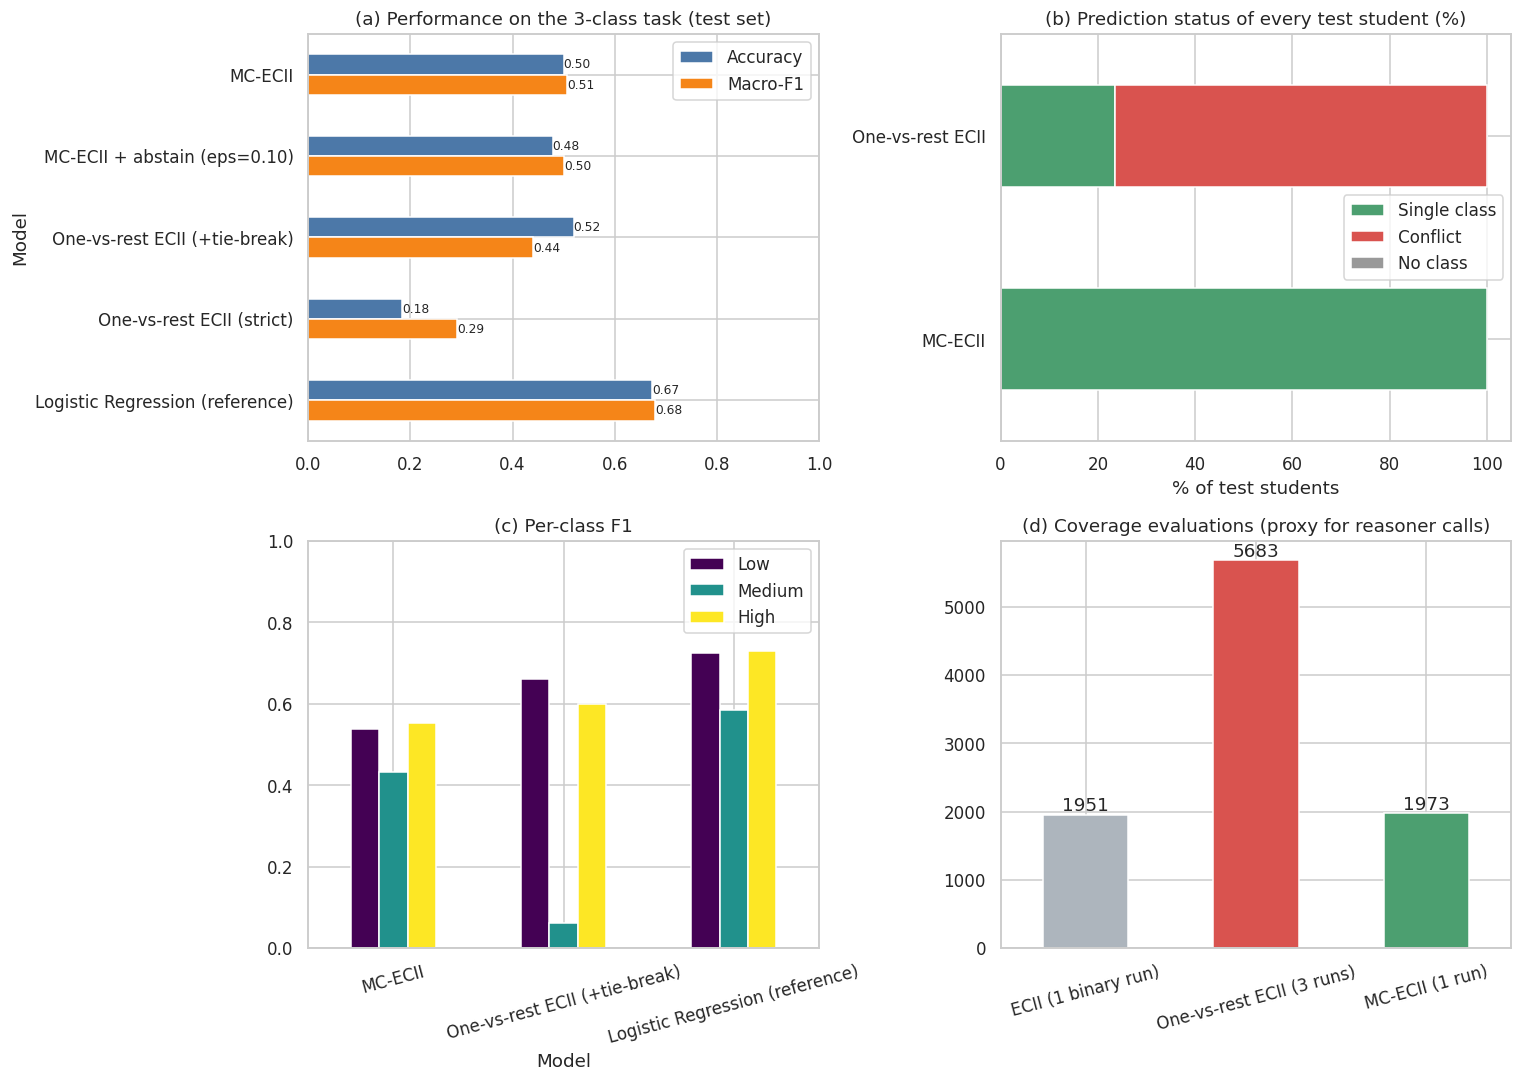

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
# (a) accuracy / macro-F1
plot = res_all.drop(index='ECII (binary, High vs Low only)')[['Accuracy', 'Macro-F1']]
plot.plot.barh(ax=axes[0, 0], color=['#4C78A8', '#F58518']); axes[0, 0].set_xlim(0, 1); axes[0, 0].invert_yaxis()
axes[0, 0].set_title('(a) Performance on the 3-class task (test set)')
for c in axes[0, 0].containers: axes[0, 0].bar_label(c, fmt='%.2f', fontsize=8)
# (b) what happens to each student
pd.DataFrame({'One-vs-rest ECII': st_pct.values, 'MC-ECII': [100, 0, 0]}, index=['Single class', 'Conflict', 'No class']).T.plot.barh(
    stacked=True, ax=axes[0, 1], color=['#4C9F70', '#D9534F', '#999999']); axes[0, 1].invert_yaxis()
axes[0, 1].set_title('(b) Prediction status of every test student (%)'); axes[0, 1].set_xlabel('% of test students')
# (c) per-class F1
pcf = res_all.loc[['MC-ECII', 'One-vs-rest ECII (+tie-break)', 'Logistic Regression (reference)'], [f'F1 {k}' for k in CLASSES]]
pcf.columns = CLASSES; pcf.plot.bar(ax=axes[1, 0], colormap='viridis'); axes[1, 0].set_ylim(0, 1); axes[1, 0].tick_params(axis='x', rotation=15)
axes[1, 0].set_title('(c) Per-class F1')
# (d) efficiency
eff['Coverage evaluations'].plot.bar(ax=axes[1, 1], color=['#adb5bd', '#D9534F', '#4C9F70']); axes[1, 1].tick_params(axis='x', rotation=15)
axes[1, 1].set_title('(d) Coverage evaluations (proxy for reasoner calls)')
for c in axes[1, 1].containers: axes[1, 1].bar_label(c)
plt.tight_layout(); plt.savefig('outputs/ecii_vs_mcecii_comparison.png'); plt.show()

,Answered (%),Accuracy on answered,Macro-F1
eps,,,
0.00,100.000,0.500,0.507
0.02,98.309,0.506,0.508
0.05,96.618,0.505,0.503
0.08,96.135,0.503,0.499
0.10,93.720,0.510,0.500
0.15,87.681,0.529,0.502
0.20,77.053,0.545,0.483


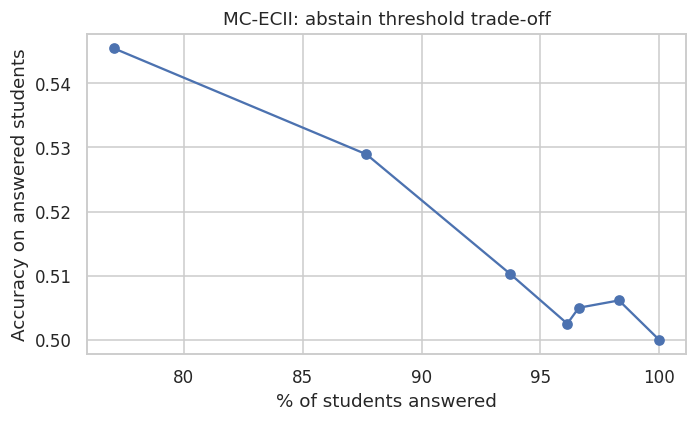

In [ ]:
# Reason 5 – abstention: trade coverage for reliability (MC-ECII only)
rows = []
for e in [0, 0.02, 0.05, 0.08, 0.10, 0.15, 0.20]:
    p, _ = mc.predict(B_te, eps=e); r = report(f'eps={e}', y_te, p)
    rows.append({'eps': e, 'Answered (%)': r['Answered (%)'], 'Accuracy on answered': r['Accuracy on answered'], 'Macro-F1': r['Macro-F1']})
ab = pd.DataFrame(rows).set_index('eps'); display(ab.round(3))
fig, ax = plt.subplots(figsize=(6.5, 4)); ax.plot(ab['Answered (%)'], ab['Accuracy on answered'], 'o-')
ax.set_xlabel('% of students answered'); ax.set_ylabel('Accuracy on answered students'); ax.set_title('MC-ECII: abstain threshold trade-off')
plt.tight_layout(); plt.savefig('outputs/mcecii_abstention_tradeoff.png'); plt.show()

## 7. Learned concepts (readable DL-style explanations)

In [ ]:
fmt = lambda idx: ' ⊓ '.join(atom_names[j] for j in idx)
print('MC-ECII - concepts grouped by class (Class(c) = argmax normalised coverage, with margin):')
for k in CLASSES:
    print(f'\n  [{k}]  {len(mc.concepts[k])} concepts')
    for idx, q, V in mc.concepts[k][:4]:
        print(f'    {fmt(idx):70s} margin={q:.2f}  V(c)=[Low {V[0]:.2f}, Med {V[1]:.2f}, High {V[2]:.2f}]')
print('\nOne-vs-rest ECII - separate concept sets (no shared coverage vector, no margin to other classes):')
for k in CLASSES:
    print(f'\n  [{k} vs rest]  {len(ov.models[k].concepts)} concepts')
    for idx, q in ov.models[k].concepts[:3]: print(f'    {fmt(idx):70s} quality={q:.2f}')

MC-ECII - concepts grouped by class (Class(c) = argmax normalised coverage, with margin):

  [Low]  25 concepts
    Assignment_Load=Low                                                    margin=0.28  V(c)=[Low 0.45, Med 0.17, High 0.09]
    High_Sleep_Hours ⊓ Assignment_Load=Low                                 margin=0.19  V(c)=[Low 0.29, Med 0.10, High 0.04]
    Low_Anxiety_Level ⊓ Assignment_Load=Low                                margin=0.16  V(c)=[Low 0.21, Med 0.04, High 0.02]
    Exam_Frequency=Medium ⊓ Assignment_Load=Low                            margin=0.16  V(c)=[Low 0.26, Med 0.10, High 0.03]

  [Medium]  6 concepts
    Assignment_Load=Medium                                                 margin=0.11  V(c)=[Low 0.45, Med 0.56, High 0.42]
    Assignment_Load=Medium ⊓ Physical_Exercise=Medium                      margin=0.09  V(c)=[Low 0.18, Med 0.26, High 0.17]
    Assignment_Load=Medium ⊓ Tuition=Medium                                margin=0.09  V(c)=[Low 0.19, Med 0.28, 

In [ ]:
summary = pd.DataFrame({
  'Aspect': ['Target handled', 'Preprocessing of target', 'Learner runs', 'Coverage evaluations', 'Single prediction per student',
             'Can abstain', 'Class link of each concept', 'Macro-F1 (3-class test)'],
  'ECII': ['2 classes', 'Pick a pair; drop the rest', '1', str(ec.counter.n), 'n/a (binary)', 'No', 'None', 'not applicable'],
  'One-vs-rest ECII': ['3 classes', '3 relabellings (k vs rest)', '3', str(ov.evals), f'No ({st_pct.iloc[1]:.0f}% conflict, {st_pct.iloc[2]:.0f}% none)',
                       'No', 'Implicit (separate runs)', f"{res.loc['One-vs-rest ECII (+tie-break)', 'Macro-F1']:.3f}"],
  'MC-ECII': ['3 classes', 'Single multiclass target (RiskClass)', '1', str(mc.counter.n), 'Yes (argmax of class scores)', 'Yes (margin threshold eps)',
              'Explicit Class(c) with margin', f"{res.loc['MC-ECII', 'Macro-F1']:.3f}"]}).set_index('Aspect')
summary.to_csv('outputs/ecii_vs_mcecii_summary.csv'); summary

,ECII,One-vs-rest ECII,MC-ECII
Aspect,,,
Target handled,2 classes,3 classes,3 classes
Preprocessing of target,Pick a pair; drop the rest,3 relabellings (k vs rest),Single multiclass target (RiskClass)
Learner runs,1,3,1
Coverage evaluations,1951,5683,1973
Single prediction per student,n/a (binary),"No (77% conflict, 0% none)",Yes (argmax of class scores)
Can abstain,No,No,Yes (margin threshold eps)
Class link of each concept,None,Implicit (separate runs),Explicit Class(c) with margin
Macro-F1 (3-class test),not applicable,0.441,0.507


In [ ]:
res_all.round(4).to_csv('outputs/ecii_vs_mcecii_results.csv'); ab.round(4).to_csv('outputs/mcecii_abstention.csv'); eff.to_csv('outputs/efficiency.csv')
shutil.make_archive('ecii_vs_mcecii_outputs', 'zip', 'outputs')
try:
    from google.colab import files; files.download('ecii_vs_mcecii_outputs.zip')
except ImportError:
    print('Saved to ./outputs and ecii_vs_mcecii_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>